# Double pendulum: where does chaos start?

A redo of the Ma'alah double pendulum project (Euler-Lagrange equations, Euler-method simulation, physical pendulum filmed with Tracker) with three upgrades:

1. **A better integrator.** Classic 4th-order Runge-Kutta (RK4) instead of forward Euler, with an energy check to prove it's accurate. The original code used forward Euler with Δt = 0.001 s for 50 s.
2. **A number for "how chaotic".** The largest Lyapunov exponent λ: how fast two almost identical releases drift apart. The original test was "do two releases 0.1° apart end up more than 0.1 m apart within 50 s".
3. **More starting angles.** Sweeps and a full map over both starting angles, the original 30 angle pairs redone, and a model of the real pendulum (rods of 24 cm and 20 cm).
4. **The films, measured instead of eyeballed.** The tracked positions from the videos are analyzed directly (section 9) and compared with the rod model, with and without friction in the middle hinge.

Run the cells from top to bottom (Runtime → Run all in Colab). With `FAST = False` everything takes roughly 40 minutes on a normal CPU. `FAST = True` uses coarser grids and shorter runs and takes about 5 minutes.

Main model (same as the original code): two 1 kg point masses on massless 1 m rods, no friction, released from rest. Angles are measured from the downward vertical.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

FAST = False   # True = quick look with coarser grids

# Physical parameters (SI units). Change these to match your own pendulum.
P = dict(m1=1.0, m2=1.0, L1=1.0, L2=1.0, g=9.81)

## 1. Equations of motion

With $\Delta = \theta_1 - \theta_2$ and $\omega_i = \dot\theta_i$, the Euler–Lagrange equations solved for the two angular accelerations are

$$\ddot\theta_1 = \frac{-g(2m_1+m_2)\sin\theta_1 - m_2 g\sin(\theta_1-2\theta_2) - 2\sin\Delta\, m_2\left(\omega_2^2 L_2 + \omega_1^2 L_1\cos\Delta\right)}{L_1\left(2m_1+m_2-m_2\cos 2\Delta\right)}$$

$$\ddot\theta_2 = \frac{2\sin\Delta\left(\omega_1^2 L_1 (m_1+m_2) + g(m_1+m_2)\cos\theta_1 + \omega_2^2 L_2 m_2\cos\Delta\right)}{L_2\left(2m_1+m_2-m_2\cos 2\Delta\right)}$$

and the total energy is

$$E = \tfrac12(m_1+m_2)L_1^2\omega_1^2 + \tfrac12 m_2 L_2^2\omega_2^2 + m_2 L_1 L_2\,\omega_1\omega_2\cos\Delta - (m_1+m_2)gL_1\cos\theta_1 - m_2 g L_2\cos\theta_2 .$$

A correct hand derivation rearranges into exactly this form. The cell after the code checks it against a computer-algebra derivation.

The state of each pendulum is $(\theta_1, \theta_2, \omega_1, \omega_2)$. The code stores many pendulums side by side in one array of shape `(4, N)`, so NumPy can simulate hundreds of starting angles at once.

In [2]:
def accel(th1, th2, w1, w2, m1, m2, L1, L2, g):
    d = th1 - th2
    sd, cd = np.sin(d), np.cos(d)
    den = 2 * m1 + m2 - m2 * np.cos(2 * d)
    a1 = (-g * (2 * m1 + m2) * np.sin(th1)
          - m2 * g * np.sin(th1 - 2 * th2)
          - 2 * sd * m2 * (w2 ** 2 * L2 + w1 ** 2 * L1 * cd)) / (L1 * den)
    a2 = (2 * sd * (w1 ** 2 * L1 * (m1 + m2)
                    + g * (m1 + m2) * np.cos(th1)
                    + w2 ** 2 * L2 * m2 * cd)) / (L2 * den)
    return a1, a2


def deriv(y, p):
    a1, a2 = accel(y[0], y[1], y[2], y[3], **p)
    return np.stack([y[2], y[3], a1, a2])


def euler_step(y, dt, p):
    # forward Euler: uses only the slope at the start of the step
    return y + dt * deriv(y, p)


def rk4_step(y, dt, p):
    # classic 4th-order Runge-Kutta: four slopes per step, weighted 1-2-2-1
    k1 = deriv(y, p)
    k2 = deriv(y + 0.5 * dt * k1, p)
    k3 = deriv(y + 0.5 * dt * k2, p)
    k4 = deriv(y + dt * k3, p)
    return y + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)


def energy(y, m1, m2, L1, L2, g):
    th1, th2, w1, w2 = y
    T = (0.5 * (m1 + m2) * L1 ** 2 * w1 ** 2 + 0.5 * m2 * L2 ** 2 * w2 ** 2
         + m2 * L1 * L2 * w1 * w2 * np.cos(th1 - th2))
    V = -(m1 + m2) * g * L1 * np.cos(th1) - m2 * g * L2 * np.cos(th2)
    return T + V


def energy_scale(p):
    # m1*g*L1 + m2*g*(L1+L2): the energy needed to lift both masses from hanging down to horizontal level
    return p["m1"] * p["g"] * p["L1"] + p["m2"] * p["g"] * (p["L1"] + p["L2"])


def initial_state(th1_deg, th2_deg):
    # released from rest at the given angles (degrees); returns shape (4, N)
    th1 = np.deg2rad(np.atleast_1d(np.asarray(th1_deg, dtype=float)))
    th2 = np.deg2rad(np.atleast_1d(np.asarray(th2_deg, dtype=float)))
    th1, th2 = np.broadcast_arrays(th1, th2)
    z = np.zeros_like(th1)
    return np.stack([th1, th2, z, z])


def integrate(y0, T, dt, step=rk4_step, p=P, every=1):
    n = int(round(T / dt))
    y = y0.copy()
    ts, ys = [0.0], [y.copy()]
    with np.errstate(all="ignore"):
        for i in range(1, n + 1):
            y = step(y, dt, p)
            if i % every == 0:
                ts.append(i * dt)
                ys.append(y.copy())
    return np.array(ts), np.array(ys)

In [3]:
# Check: derive the equations from the Lagrangian with sympy and compare at 2000 random states.
import sympy as sp

t = sp.symbols("t")
m1, m2, L1, L2, g = sp.symbols("m1 m2 L1 L2 g", positive=True)
q1, q2 = sp.Function("q1")(t), sp.Function("q2")(t)
x1, y1 = L1 * sp.sin(q1), -L1 * sp.cos(q1)
x2, y2 = x1 + L2 * sp.sin(q2), y1 - L2 * sp.cos(q2)
Tk = sp.Rational(1, 2) * (m1 * (x1.diff(t) ** 2 + y1.diff(t) ** 2) + m2 * (x2.diff(t) ** 2 + y2.diff(t) ** 2))
Vp = m1 * g * y1 + m2 * g * y2
Lag = Tk - Vp
A1, A2, W1, W2, Q1, Q2 = sp.symbols("A1 A2 W1 W2 Q1 Q2")
eqs = [sp.diff(Lag.diff(q.diff(t)), t) - Lag.diff(q) for q in (q1, q2)]
eqs = [e.subs({q1.diff(t, 2): A1, q2.diff(t, 2): A2}).subs({q1.diff(t): W1, q2.diff(t): W2}).subs({q1: Q1, q2: Q2})
       for e in eqs]
sol = sp.solve(eqs, [A1, A2], dict=True)[0]
f_sym = sp.lambdify((Q1, Q2, W1, W2, m1, m2, L1, L2, g), [sol[A1], sol[A2]], "numpy")

rng = np.random.default_rng(1)
worst = 0.0
for _ in range(2000):
    th = rng.uniform(-np.pi, np.pi, 2); w = rng.uniform(-8, 8, 2)
    pm = dict(m1=rng.uniform(0.2, 3), m2=rng.uniform(0.2, 3), L1=rng.uniform(0.2, 2), L2=rng.uniform(0.2, 2), g=9.81)
    ref = np.array(f_sym(th[0], th[1], w[0], w[1], **pm), dtype=float)
    mine = np.array(accel(th[0], th[1], w[0], w[1], **pm))
    worst = max(worst, np.max(np.abs(ref - mine) / (1 + np.abs(ref))))
print(f"largest relative difference from the sympy derivation: {worst:.1e}  (machine precision is about 1e-16)")

largest relative difference from the sympy derivation: 1.3e-14  (machine precision is about 1e-16)


## 2. Why forward Euler drifts

Forward Euler takes the slope at the start of each step and walks in a straight line. For anything that swings back and forth, that straight line always lands slightly outside the true curve, so every step adds a little energy. The error per second shrinks only in proportion to the step size $\Delta t$ (it's a first-order method). RK4 samples the slope four times per step and its error shrinks like $\Delta t^4$.

Extra energy matters a lot here: more energy means bigger swings, and bigger swings are exactly what make the double pendulum chaotic. So Euler can make a release look chaotic when it isn't.

In [4]:
# Plot style (colors checked for colorblind safety and contrast)
SURF, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
        "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.family": "sans-serif", "font.size": 9.5,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10.5,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "legend.fontsize": 8.5, "legend.labelcolor": INK2,
    "savefig.dpi": 300, "savefig.bbox": "tight",
})


def suptitle(fig, title, sub):
    fig.text(0.0, 1.0, title, ha="left", va="bottom", fontsize=11.5, fontweight="bold", color=INK,
             transform=fig.transFigure)
    fig.text(0.0, 0.985, sub, ha="left", va="top", fontsize=8.8, color=INK2, transform=fig.transFigure)

Euler, Δt = 0.01 s     energy error after 10 s: 7.7e-01   after 60 s: 6.0e+00


Euler, Δt = 0.001 s    energy error after 10 s: 6.4e-02   after 60 s: 3.7e-01


Euler, Δt = 0.0001 s   energy error after 10 s: 6.3e-03   after 60 s: 3.8e-02


RK4, Δt = 0.002 s      energy error after 10 s: 5.9e-09   after 60 s: 1.1e-08


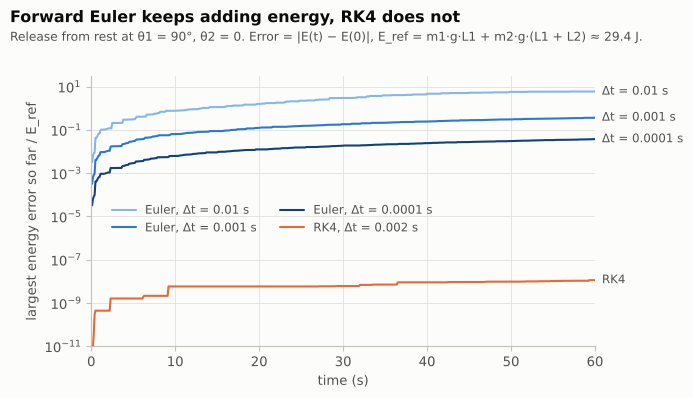

In [5]:
# Figure 1: energy error over 60 s for a release at theta1 = 90 deg, theta2 = 0
y0 = initial_state(90, 0)
runs = [("Euler, Δt = 0.01 s", euler_step, 0.01, RAMP[3]),
        ("Euler, Δt = 0.001 s", euler_step, 0.001, RAMP[7]),
        ("Euler, Δt = 0.0001 s", euler_step, 0.0001, RAMP[11]),
        ("RK4, Δt = 0.002 s", rk4_step, 0.002, ORANGE)]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for label, step, dt, color in runs:
    ts, ys = integrate(y0, 60.0, dt, step=step, every=int(round(0.1 / dt)))
    E = energy(ys[:, :, 0].T, **P)
    err = np.maximum.accumulate(np.abs(E - E[0]) / energy_scale(P))[1:]   # largest error so far
    print(f"{label:22s} energy error after 10 s: {err[99]:.1e}   after 60 s: {err[-1]:.1e}")
    ax.plot(ts[1:], err, color=color, label=label)
    ax.annotate(label.split(", ")[1] if label.startswith("Euler") else "RK4", (ts[-1], err[-1]),
                xytext=(5, 0), textcoords="offset points", va="center", fontsize=8.5, color=INK2)
ax.set_yscale("log"); ax.set_ylim(1e-11, 30); ax.set_xlim(0, 60)
ax.set_xlabel("time (s)"); ax.set_ylabel("largest energy error so far / E_ref")
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.47), ncol=2)
suptitle(fig, "Forward Euler keeps adding energy, RK4 does not",
         "Release from rest at θ1 = 90°, θ2 = 0. Error = |E(t) − E(0)|, "
         f"E_ref = m1·g·L1 + m2·g·(L1 + L2) ≈ {energy_scale(P):.1f} J.")
fig.subplots_adjust(top=0.86)
fig.savefig("fig1_energy_drift.png")
plt.show()

## 3. Measuring chaos: the Lyapunov exponent

Start a second "twin" pendulum $10^{-8}$ away from the first in $(\theta_1,\theta_2,\omega_1,\omega_2)$ space and watch the gap $d(t)$.

* In **chaotic** motion the gap grows exponentially, $d \approx d_0 e^{\lambda t}$, with $\lambda > 0$.
* In **regular** motion it grows at most in proportion to time, so the measured $\lambda$ sinks toward 0 the longer you run.

The gap can't be allowed to grow forever (it would saturate at the size of the whole motion), so every 0.05 s the code adds $\ln(d/d_0)$ to a running total and pulls the twin back to distance $d_0$ in the same direction (the Benettin method). Then $\lambda = $ total $/$ run time.

Because runs are finite, regular releases still show a small positive $\lambda$ (roughly $\ln t / t$). Over 400 s almost all of them sit below 0.03 /s, while chaotic ones sit above 0.1 /s, so the labels used here are **regular** ($\lambda < 0.03$ /s), **weakly chaotic** (0.03 to 0.1 /s) and **chaotic** ($\lambda > 0.1$ /s). The 0.1 /s line is drawn as the chaos threshold in the plots.

The code also records when either arm first goes over the top (a "flip").

In [6]:
def lyapunov(y0, T=200.0, dt=0.002, step=rk4_step, p=P, d0=1e-8, renorm_dt=0.05, seed=0, checkpoints=None,
             energy_fn=None, escale=None):
    rng = np.random.default_rng(seed)
    N = y0.shape[1]
    u = rng.normal(size=y0.shape)
    u /= np.linalg.norm(u, axis=0)
    Y = np.concatenate([y0, y0 + d0 * u], axis=1)           # reference | twin
    k = max(1, int(round(renorm_dt / dt)))
    block = k * dt
    n_blocks = int(round(T / block))
    cp_blocks = {int(round(tc / block)): tc for tc in sorted(checkpoints or [])}
    lam_at, log_sum = {}, np.zeros(N)
    flip_lower, flip_upper = np.full(N, np.nan), np.full(N, np.nan)
    if energy_fn is None:                                   # default: the point-mass model
        energy_fn, escale = (lambda y: energy(y, **p)), energy_scale(p)
    E0 = energy_fn(y0)
    with np.errstate(all="ignore"):
        for b in range(1, n_blocks + 1):
            for _ in range(k):
                Y = step(Y, dt, p)
            ref, twin = Y[:, :N], Y[:, N:]
            diff = twin - ref
            d = np.linalg.norm(diff, axis=0)
            log_sum += np.log(d / d0)
            Y[:, N:] = ref + diff * (d0 / d)                  # pull the twin back
            t_now = b * block
            new = np.isnan(flip_lower) & (np.abs(ref[1]) > np.pi); flip_lower[new] = t_now
            new = np.isnan(flip_upper) & (np.abs(ref[0]) > np.pi); flip_upper[new] = t_now
            if b in cp_blocks:
                lam_at[cp_blocks[b]] = log_sum / t_now
        E1 = energy_fn(Y[:, :N])
    lam = log_sum / (n_blocks * block)
    lam[~np.isfinite(lam)] = np.nan
    for v in lam_at.values():
        v[~np.isfinite(v)] = np.nan
    return dict(lam=lam, lam_at=lam_at, drift=np.abs(E1 - E0) / escale,
                flip_lower=flip_lower, flip_upper=flip_upper)


def two_configs(ang):
    # lower arm hanging straight down (theta2 = 0) and both arms in a straight line (theta2 = theta1)
    return np.concatenate([initial_state(ang, 0), initial_state(ang, ang)], axis=1)


THRESH = 0.1   # 1/s, chaos threshold for the long runs


def onset(ang, lam, thr):
    # first chaotic angle, and the angle above which every start is chaotic
    chaotic = lam > thr
    first = ang[np.argmax(chaotic)] if chaotic.any() else np.nan
    reg = np.where(~chaotic)[0]
    always = ang[reg[-1] + 1] if len(reg) and reg[-1] + 1 < len(ang) else np.nan
    return first, always

## 4. Sweep over the upper arm's starting angle

Two ways to release from rest, for $\theta_1$ from 0° to 180°:

* **Lower arm hanging straight down**: $\theta_2 = 0$
* **Both arms in a straight line**: $\theta_2 = \theta_1$

In [7]:
step_deg, T_sweep = (1.0, 200) if FAST else (0.25, 400)
ang = np.arange(0, 180.0001, step_deg)
n = len(ang)
t0 = time.time()
sw = lyapunov(two_configs(ang), T=T_sweep, dt=0.002, checkpoints=[50, 100, 200, 400] if not FAST else [50, 100, 200])
print(f"sweep: {2 * n} releases, {T_sweep} s each, took {time.time() - t0:.0f} s; "
      f"largest energy error {np.nanmax(sw['drift']):.1e} of E_ref")

lam_down, lam_line = sw["lam"][:n], sw["lam"][n:]
for name, lam in (("theta2 = 0      ", lam_down), ("theta2 = theta1 ", lam_line)):
    first, always = onset(ang, lam, THRESH)
    print(f"{name}: first chaotic start {first:g} deg, chaotic for every start from {always:g} deg")

import csv
with open("lyapunov_sweep.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["theta1_deg", "lambda_theta2_0", "lambda_theta2_eq_theta1",
                "first_lower_flip_s_theta2_0", "first_lower_flip_s_theta2_eq_theta1"])
    for i in range(n):
        w.writerow([ang[i], f"{lam_down[i]:.5f}", f"{lam_line[i]:.5f}",
                    sw["flip_lower"][i], sw["flip_lower"][n + i]])
print("saved lyapunov_sweep.csv")

sweep: 1442 releases, 400 s each, took 234 s; largest energy error 3.2e-06 of E_ref
theta2 = 0      : first chaotic start 66.5 deg, chaotic for every start from 82.75 deg
theta2 = theta1 : first chaotic start 79.25 deg, chaotic for every start from 79.25 deg
saved lyapunov_sweep.csv


### Why 90°? An energy argument

For the lower arm to go over the top, the pendulum needs at least the energy of the cheapest "lower arm pointing up" position, which is $\theta_1 = 0, \theta_2 = 180°$: $V = -(m_1+m_2)gL_1 + m_2 g L_2$. A release from rest has $E = -(m_1+m_2)gL_1\cos\theta_1 - m_2 g L_2\cos\theta_2$, and energy is conserved, so a flip is only possible if

$$(m_1+m_2)L_1\cos\theta_1 + m_2 L_2\cos\theta_2 \le (m_1+m_2)L_1 - m_2 L_2 .$$

With equal masses and lengths this is $2\cos\theta_1 + \cos\theta_2 \le 1$:

* lower arm hanging down ($\theta_2 = 0$): $\cos\theta_1 \le 0$, so **$\theta_1 \ge 90°$**
* arms in a line ($\theta_2 = \theta_1$): $\cos\theta_1 \le 1/3$, so **$\theta_1 \ge 70.5°$**

Below these angles the lower arm physically cannot flip, whatever the integrator says. (The upper arm needs $2\cos\theta_1 + \cos\theta_2 \le -1$.)

In [8]:
def K_value(th1_deg, th2_deg, p=P):
    return ((p["m1"] + p["m2"]) * p["L1"] * np.cos(np.deg2rad(th1_deg))
            + p["m2"] * p["L2"] * np.cos(np.deg2rad(th2_deg)))


def flip_limits(p=P):
    a, b = (p["m1"] + p["m2"]) * p["L1"], p["m2"] * p["L2"]
    return a - b, -a + b          # lower-arm flip limit, upper-arm flip limit


def flip_angle(th2_of_th1, p=P):
    a = np.linspace(0, 180, 180001)
    ok = K_value(a, th2_of_th1(a), p) <= flip_limits(p)[0] + 1e-12
    return a[np.argmax(ok)] if ok.any() else np.nan


flip_down, flip_line = flip_angle(lambda a: 0 * a), flip_angle(lambda a: a)
print(f"energy allows the lower arm to flip from {flip_down:.1f} deg (theta2 = 0) and {flip_line:.1f} deg (theta2 = theta1)")

# sanity check against the simulation: no lower-arm flip should ever happen below these angles
for name, sl, lim in (("theta2 = 0", slice(0, n), flip_down), ("theta2 = theta1", slice(n, 2 * n), flip_line)):
    flipped = ~np.isnan(sw["flip_lower"][sl])
    lowest = ang[flipped].min() if flipped.any() else np.nan
    print(f"{name}: lowest start whose lower arm flipped = {lowest:g} deg (energy limit {lim:.1f} deg)")

energy allows the lower arm to flip from 90.0 deg (theta2 = 0) and 70.5 deg (theta2 = theta1)
theta2 = 0: lowest start whose lower arm flipped = 90.25 deg (energy limit 90.0 deg)
theta2 = theta1: lowest start whose lower arm flipped = 79.25 deg (energy limit 70.5 deg)


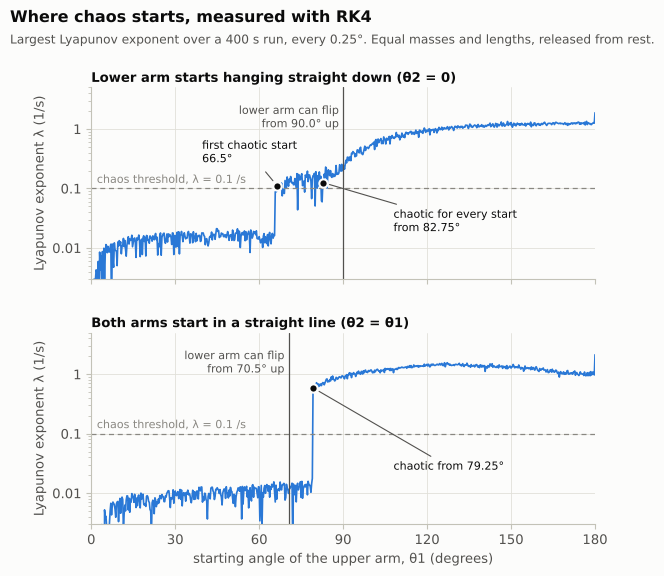

In [9]:
# Figure 2: lambda vs starting angle
panels = [(lam_down, "Lower arm starts hanging straight down (θ2 = 0)", flip_down),
          (lam_line, "Both arms start in a straight line (θ2 = θ1)", flip_line)]
fig, axes = plt.subplots(2, 1, figsize=(6.5, 5.6), sharex=True)
for ax, (lam, title, flip_deg) in zip(axes, panels):
    ax.plot(ang, lam, color=BLUE, lw=1.2)
    ax.set_yscale("log"); ax.set_ylim(0.003, 5)
    ax.axhline(THRESH, color=MUTED, lw=0.9, ls=(0, (4, 3)))
    ax.text(2, THRESH * 1.12, "chaos threshold, λ = 0.1 /s", fontsize=8, color=MUTED, va="bottom")
    ax.axvline(flip_deg, color=INK2, lw=0.9)
    ax.text(flip_deg - 1.5, 2.6, f"lower arm can flip\nfrom {flip_deg:.1f}° up", fontsize=8, color=INK2,
            ha="right", va="top")
    first, always = onset(ang, lam, THRESH)
    marks = ([(first, f"chaotic from {first:g}°", (0.60, 0.30))] if first == always else
             [(first, f"first chaotic start\n{first:g}°", (0.22, 0.66)),
              (always, f"chaotic for every start\nfrom {always:g}°", (0.60, 0.30))])
    for x, txt, pos in marks:
        yv = np.interp(x, ang, lam)
        ax.plot([x], [yv], "o", ms=6, color=INK, mec=SURF, mew=1.5, zorder=5)
        ax.annotate(txt, (x, yv), xytext=pos, textcoords="axes fraction", fontsize=8, color=INK,
                    va="center", arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8, shrinkA=3, shrinkB=5))
    ax.set_title(title, fontsize=9.5, pad=4)
    ax.set_ylabel("Lyapunov exponent λ (1/s)")
    ax.set_yticks([0.01, 0.1, 1]); ax.set_yticklabels(["0.01", "0.1", "1"])
axes[-1].set_xlabel("starting angle of the upper arm, θ1 (degrees)")
axes[-1].set_xlim(0, 180); axes[-1].set_xticks(range(0, 181, 30))
suptitle(fig, "Where chaos starts, measured with RK4",
         f"Largest Lyapunov exponent over a {T_sweep} s run, every {step_deg:g}°. "
         "Equal masses and lengths, released from rest.")
fig.subplots_adjust(top=0.89, hspace=0.28)
fig.savefig("fig2_lyapunov_vs_angle.png")
plt.show()

## 5. What Euler would have told you

Same analysis, but with forward Euler at different step sizes. Runs are 50 s long here (Euler's energy gain makes long runs meaningless), so the threshold is raised to λ > 0.3 /s ("strong chaos"), and RK4 is run the same way for a fair comparison.

Euler comparison took 100 s
θ2 = 0 (lower arm hanging down): RK4 91 deg | Euler dt=0.01: 1, dt=0.005: 17, dt=0.003: 41, dt=0.002: 58, dt=0.001: 76, dt=0.0005: 84, dt=0.0003: 88, dt=0.0002: 89, dt=0.0001: 91
θ2 = θ1 (arms in a line): RK4 80 deg | Euler dt=0.01: 2, dt=0.005: 29, dt=0.003: 51, dt=0.002: 70, dt=0.001: 76, dt=0.0005: 79, dt=0.0003: 79, dt=0.0002: 79, dt=0.0001: 79


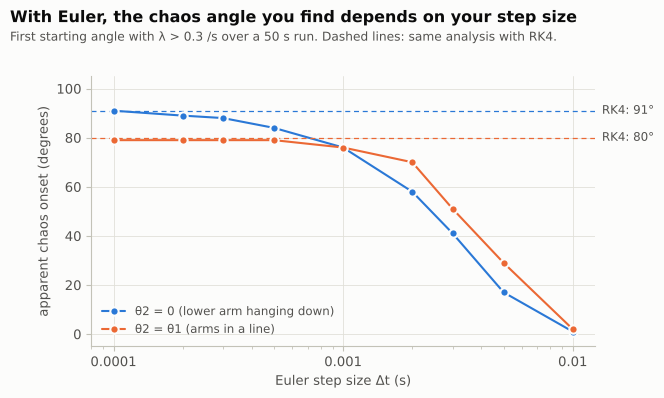

In [10]:
STRONG = 0.3
ang1 = np.arange(0, 180.0001, 1.0); n1 = len(ang1)
y0 = two_configs(ang1)
dts = np.array([0.01, 0.005, 0.003, 0.002, 0.001, 0.0005, 0.0003, 0.0002, 0.0001])
if FAST:
    dts = dts[dts >= 0.0003]
t0 = time.time()
lam_e = np.array([lyapunov(y0, T=50, dt=dt, step=euler_step)["lam"] for dt in dts])
lam_r = lyapunov(y0, T=50, dt=0.002)["lam"]
print(f"Euler comparison took {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for sl, label, color in ((slice(0, n1), "θ2 = 0 (lower arm hanging down)", BLUE),
                         (slice(n1, 2 * n1), "θ2 = θ1 (arms in a line)", ORANGE)):
    on = np.array([onset(ang1, l[sl], STRONG)[0] for l in lam_e])
    rk = onset(ang1, lam_r[sl], STRONG)[0]
    print(f"{label}: RK4 {rk:g} deg | Euler " + ", ".join(f"dt={dt:g}: {o:g}" for dt, o in zip(dts, on)))
    ax.axhline(rk, color=color, lw=0.9, ls=(0, (4, 3)))
    ax.plot(dts, on, "-o", color=color, ms=6, mec=SURF, mew=1.5, label=label)
    ax.annotate(f"RK4: {rk:g}°", (1.0, rk), xycoords=("axes fraction", "data"), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK2, annotation_clip=False)
ax.set_xscale("log"); ax.set_xlim(8e-5, 1.25e-2)
ax.set_xticks([1e-4, 1e-3, 1e-2]); ax.set_xticklabels(["0.0001", "0.001", "0.01"])
ax.set_ylim(-5, 105); ax.set_yticks(range(0, 101, 20))
ax.set_xlabel("Euler step size Δt (s)"); ax.set_ylabel("apparent chaos onset (degrees)")
ax.legend(loc="lower left")
suptitle(fig, "With Euler, the chaos angle you find depends on your step size",
         "First starting angle with λ > 0.3 /s over a 50 s run. Dashed lines: same analysis with RK4.")
fig.subplots_adjust(top=0.86)
fig.savefig("fig3_euler_step_size.png")
plt.show()

## 6. Chaos map over both starting angles

Every pair $(\theta_1, \theta_2)$, released from rest. The map is symmetric: starting at $(-\theta_1, -\theta_2)$ is the mirror image of $(\theta_1, \theta_2)$, so only half is simulated. The black curves are the energy limits from section 4.

map: 16471 releases, took 864 s; largest energy error 6.9e-05 of E_ref


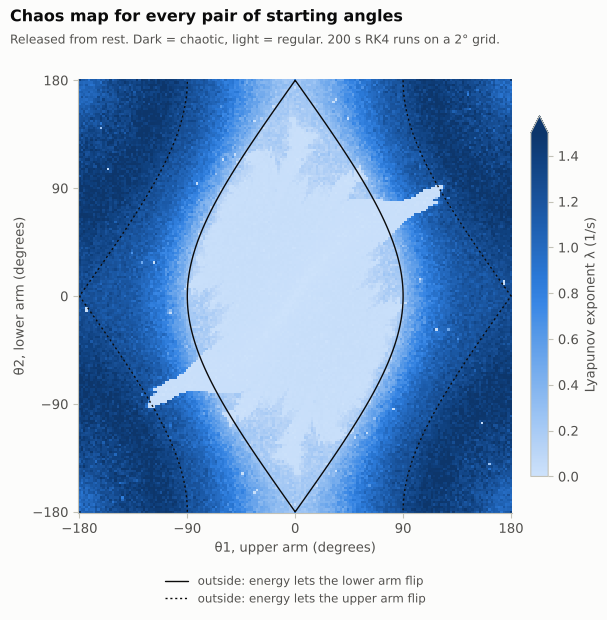

chaotic share of starts where the lower arm can't flip: 23.3%; where it can: 97.7%


In [11]:
grid_deg, T_map = (6.0, 100) if FAST else (2.0, 200)
th1g = np.arange(0, 180.0001, grid_deg)
th2g = np.arange(-180, 180.0001, grid_deg)
A1, A2 = np.meshgrid(th1g, th2g, indexing="ij")
t0 = time.time()
mp = lyapunov(initial_state(A1.ravel(), A2.ravel()), T=T_map, dt=0.004)
lam_map = mp["lam"].reshape(A1.shape)
print(f"map: {A1.size} releases, took {time.time() - t0:.0f} s; largest energy error {np.nanmax(mp['drift']):.1e} of E_ref")

full = np.concatenate([lam_map[:0:-1, ::-1], lam_map], axis=0)    # mirror to cover theta1 < 0
th1_full = np.concatenate([-th1g[:0:-1], th1g])
fig = plt.figure(figsize=(6.2, 6.1))
side = 0.70                                    # square plot: same size in inches both ways
ax = fig.add_axes([0.11, 0.20, side, side * 6.2 / 6.1])
cax = fig.add_axes([0.11 + side + 0.03, 0.26, 0.028, side * 6.2 / 6.1 - 0.12])
cax.grid(False)
h = grid_deg / 2
im = ax.imshow(full.T, origin="lower", cmap=LinearSegmentedColormap.from_list("blue_seq", RAMP),
               vmin=0, vmax=1.5, extent=[th1_full[0] - h, th1_full[-1] + h, th2g[0] - h, th2g[-1] + h],
               interpolation="nearest", aspect="equal")
ax.grid(False)
T1, T2 = np.meshgrid(np.linspace(-180, 180, 721), np.linspace(-180, 180, 721), indexing="ij")
lo, up = flip_limits()
ax.contour(T1, T2, K_value(T1, T2), levels=[lo], colors=[INK], linewidths=1.0)
ax.contour(T1, T2, K_value(T1, T2), levels=[up], colors=[INK], linewidths=1.0, linestyles=[(0, (1.5, 2))])
ax.set_xticks(range(-180, 181, 90)); ax.set_yticks(range(-180, 181, 90))
ax.set_xlabel("θ1, upper arm (degrees)"); ax.set_ylabel("θ2, lower arm (degrees)")
cb = fig.colorbar(im, cax=cax, extend="max")
cb.set_label("Lyapunov exponent λ (1/s)", color=INK2)
cb.outline.set_edgecolor(AXIS); cb.ax.tick_params(color=AXIS, labelcolor=INK2)
ax.legend(handles=[Line2D([], [], color=INK, lw=1.0, label="outside: energy lets the lower arm flip"),
                   Line2D([], [], color=INK, lw=1.0, ls=(0, (1.5, 2)), label="outside: energy lets the upper arm flip")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=1)
suptitle(fig, "Chaos map for every pair of starting angles",
         f"Released from rest. Dark = chaotic, light = regular. {T_map} s RK4 runs on a {grid_deg:g}° grid.")
fig.savefig("fig4_chaos_map.png")
plt.show()

inside = K_value(A1, A2) > lo
print(f"chaotic share of starts where the lower arm can't flip: {np.mean(lam_map[inside] > THRESH):.1%}; "
      f"where it can: {np.mean(lam_map[~inside] > THRESH):.1%}")

## 7. The original 30 starting pairs, redone

The original `simulation_sweep.py` tested 30 pairs $(\theta_1, \theta_2)$. Three ways of judging each one:

1. **The original test, exactly as written:** forward Euler with Δt = 0.001 s, a twin release with both angles 0.1° larger, "chaotic" if the two tips end up more than 0.1 m apart within 50 s.
2. **The same test with RK4.**
3. **The Lyapunov exponent** from section 3 (RK4, 400 s).

The table also lists what the write-up concluded for each pair (its results section). It doesn't give a verdict for (45°, 105°) and (45°, 120°).

In [12]:
PAIRS = [(30, 30), (30, 60), (30, 90), (30, 105), (30, 120),
         (45, 30), (45, 60), (45, 90), (45, 105), (45, 120),
         (60, 30), (60, 45), (60, 60), (60, 90), (60, 105), (60, 120),
         (75, 15), (75, 60), (75, 75), (75, 90),
         (90, 0), (90, 30), (90, 45), (90, 60), (90, 90),
         (120, 30), (120, 45), (120, 60), (120, 90), (120, 120)]
PAPER = {(30, 30): "stable", (30, 60): "stable", (30, 90): "stable", (30, 105): "stable", (30, 120): "chaotic",
         (45, 30): "stable", (45, 60): "stable", (45, 90): "stable", (45, 105): "not stated", (45, 120): "not stated",
         (60, 30): "stable", (60, 45): "chaotic", (60, 60): "stable", (60, 90): "stable", (60, 105): "chaotic",
         (60, 120): "chaotic", (75, 15): "stable", (75, 60): "stable", (75, 75): "stable", (75, 90): "chaotic",
         (90, 0): "chaotic", (90, 30): "chaotic", (90, 45): "chaotic", (90, 60): "chaotic", (90, 90): "chaotic",
         (120, 30): "chaotic", (120, 45): "chaotic", (120, 60): "chaotic", (120, 90): "chaotic", (120, 120): "chaotic"}


def tips(y, p=P):
    x1, y1 = p["L1"] * np.sin(y[0]), -p["L1"] * np.cos(y[0])
    return x1 + p["L2"] * np.sin(y[1]), y1 - p["L2"] * np.cos(y[1])


def separation_time(th1, th2, step, dt, T=50.0, delta_deg=0.1, thresh=0.1, p=P):
    # the original chaos test: first time the two tips are more than `thresh` metres apart (NaN = never)
    a = initial_state(th1, th2)
    b = initial_state(np.asarray(th1, float) + delta_deg, np.asarray(th2, float) + delta_deg)
    N = a.shape[1]
    Y = np.concatenate([a, b], axis=1)
    t_sep = np.full(N, np.nan)
    with np.errstate(all="ignore"):
        for i in range(1, int(round(T / dt)) + 1):
            Y = step(Y, dt, p)
            xa, ya = tips(Y[:, :N], p)
            xb, yb = tips(Y[:, N:], p)
            new = np.isnan(t_sep) & (np.hypot(xa - xb, ya - yb) > thresh)
            t_sep[new] = i * dt
    return t_sep


def label(lam):
    return "regular" if lam < 0.03 else ("weakly chaotic" if lam <= 0.1 else "chaotic")


th1p = np.array([a for a, _ in PAIRS], float)
th2p = np.array([b for _, b in PAIRS], float)
t0 = time.time()
t_euler = separation_time(th1p, th2p, euler_step, 0.001)    # exactly the original method
t_rk4 = separation_time(th1p, th2p, rk4_step, 0.001)
T_pairs = 100 if FAST else 400
lam_p = lyapunov(initial_state(th1p, th2p), T=T_pairs, dt=0.002)["lam"]
print(f"took {time.time() - t0:.0f} s\n")
if FAST:
    print("FAST mode: 100 s runs are too short to tell regular from weakly chaotic, so some labels below are off.\n"
          "Use FAST = False for the real verdicts.\n")

fmt = lambda t: "never" if np.isnan(t) else f"{t:.1f} s"
print(f"{'start':>11} | {'write-up':>10} | {'Euler test':>10} | {'RK4 test':>8} | {'lambda':>7} | RK4 + lambda verdict")
rows = []
for i, (a, b) in enumerate(PAIRS):
    v = label(lam_p[i])
    flag = "  <-- changed" if PAPER[(a, b)] != "not stated" and ((PAPER[(a, b)] == "stable") != (v == "regular")) else ""
    print(f"({a:3d},{b:4d}) | {PAPER[(a, b)]:>10} | {fmt(t_euler[i]):>10} | {fmt(t_rk4[i]):>8} | {lam_p[i]:7.3f} | {v}{flag}")
    rows.append([a, b, PAPER[(a, b)], t_euler[i], t_rk4[i], round(float(lam_p[i]), 4), v])

import csv
with open("original_pairs_redone.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["theta1_deg", "theta2_deg", "write_up_verdict", "euler_split_time_s", "rk4_split_time_s",
                "lyapunov_per_s", "verdict"])
    w.writerows(rows)
print("\nsaved original_pairs_redone.csv ('Euler test' / 'RK4 test' = time the 0.1 deg twins split by 0.1 m)")

took 41 s

      start |   write-up | Euler test | RK4 test |  lambda | RK4 + lambda verdict
( 30,  30) |     stable |      never |    never |   0.011 | regular
( 30,  60) |     stable |      never |    never |   0.008 | regular
( 30,  90) |     stable |     24.7 s |   32.7 s |   0.087 | weakly chaotic  <-- changed
( 30, 105) |     stable |     23.9 s |   19.8 s |   0.182 | chaotic  <-- changed
( 30, 120) |    chaotic |     10.9 s |   18.1 s |   0.168 | chaotic
( 45,  30) |     stable |      never |    never |   0.010 | regular
( 45,  60) |     stable |      never |    never |   0.010 | regular
( 45,  90) |     stable |     47.2 s |    never |   0.013 | regular
( 45, 105) | not stated |     26.9 s |    never |   0.120 | chaotic
( 45, 120) | not stated |     18.9 s |   14.2 s |   0.315 | chaotic
( 60,  30) |     stable |     31.9 s |    never |   0.015 | regular
( 60,  45) |    chaotic |     41.7 s |    never |   0.015 | regular  <-- changed
( 60,  60) |     stable |      never |    nev

Two things to notice:

* **The 0.1 m test is too generous.** With Euler it flags 25 of the 30 pairs within 50 s, because Euler's extra energy and the slow drift of even regular motion both push the twins apart eventually. The write-up's verdicts don't follow the test strictly either (for example the Euler twins for (60°, 90°) split after 16 s, yet it's listed as stable), so the original verdicts partly came from looking at the plots.
* **Six verdicts change** (marked in the table): (60°, 45°) and (120°, 90°) are regular, not chaotic, and (30°, 90°), (30°, 105°), (60°, 90°) and (75°, 15°) show chaos the write-up missed. (120°, 90°) sits in a narrow tongue of regular motion that reaches into the chaotic region. It's only a few degrees wide there, so a real release with a 2° error could easily miss it.

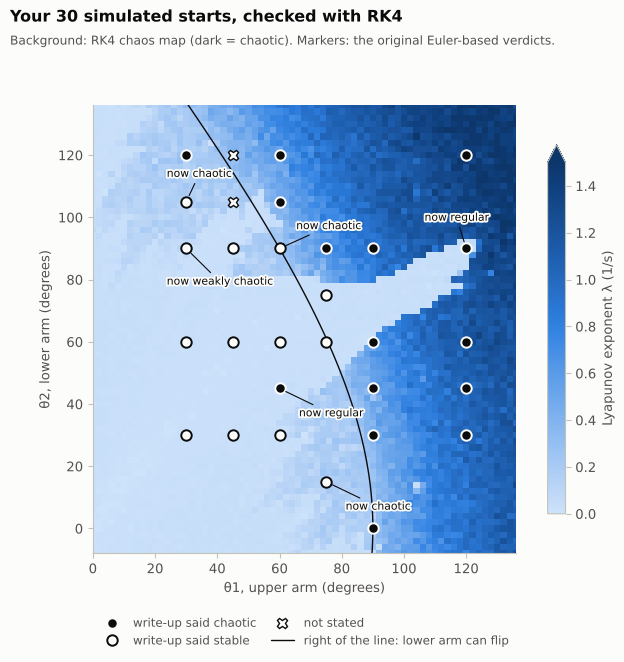

In [13]:
# Figure 5: the 30 pairs on the RK4 chaos map from section 6
import matplotlib.patheffects as pe
HALO = [pe.withStroke(linewidth=2.6, foreground=SURF)]
MARK = {"chaotic": dict(marker="o", mfc=INK, mec=SURF, ms=7.5, mew=1.4),
        "stable": dict(marker="o", mfc=SURF, mec=INK, ms=7.5, mew=1.4),
        "borderline": dict(marker="D", mfc=MUTED, mec=SURF, ms=6.5, mew=1.2),
        "not stated": dict(marker="X", mfc=SURF, mec=INK, ms=7.5, mew=1.0)}

fig = plt.figure(figsize=(6.4, 6.6))
side = 0.70
ax = fig.add_axes([0.11, 0.20, side, side * 6.4 / 6.6])
cax = fig.add_axes([0.11 + side + 0.03, 0.26, 0.028, side * 6.4 / 6.6 - 0.12])
cax.grid(False)
h = grid_deg / 2
im = ax.imshow(lam_map.T, origin="lower", cmap=LinearSegmentedColormap.from_list("blue_seq", RAMP), vmin=0, vmax=1.5,
               extent=[th1g[0] - h, th1g[-1] + h, th2g[0] - h, th2g[-1] + h], interpolation="nearest", aspect="auto")
ax.set_xlim(0, 136); ax.set_ylim(-8, 136); ax.set_aspect("equal"); ax.grid(False)
T1z, T2z = np.meshgrid(np.linspace(0, 140, 561), np.linspace(-10, 140, 601), indexing="ij")
ax.contour(T1z, T2z, K_value(T1z, T2z), levels=[flip_limits()[0]], colors=[INK], linewidths=1.0)
offsets = {(60, 45): (14, -18), (120, 90): (-30, 22), (60, 90): (12, 16), (30, 105): (-14, 20),
           (30, 90): (-14, -24), (75, 15): (14, -18)}
for i, (a, b) in enumerate(PAIRS):
    said, now = PAPER[(a, b)], label(lam_p[i])
    ax.plot([a], [b], ls="none", zorder=5, **MARK[said])
    if said != "not stated" and ((said == "stable") != (now == "regular")):
        ax.annotate(f"now {now}", (a, b), xytext=offsets.get((a, b), (10, 10)), textcoords="offset points",
                    fontsize=7.8, color=INK, path_effects=HALO, zorder=6, va="center",
                    arrowprops=dict(arrowstyle="-", color=INK, lw=0.8, shrinkA=1, shrinkB=5))
cb = fig.colorbar(im, cax=cax, extend="max")
cb.set_label("Lyapunov exponent λ (1/s)", color=INK2); cb.outline.set_edgecolor(AXIS)
cb.ax.tick_params(color=AXIS, labelcolor=INK2)
ax.set_xlabel("θ1, upper arm (degrees)"); ax.set_ylabel("θ2, lower arm (degrees)")
ax.legend(handles=[Line2D([], [], ls="none", label="write-up said chaotic", **MARK["chaotic"]),
                   Line2D([], [], ls="none", label="write-up said stable", **MARK["stable"]),
                   Line2D([], [], ls="none", label="not stated", **MARK["not stated"]),
                   Line2D([], [], color=INK, lw=1.0, label="right of the line: lower arm can flip")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, columnspacing=1.2)
suptitle(fig, "Your 30 simulated starts, checked with RK4",
         "Background: RK4 chaos map (dark = chaotic). Markers: the original Euler-based verdicts.")
fig.savefig("fig5_original_pairs_checked.png")
plt.show()

### What this does to the write-up's conclusions

* **"θ1 matters more than θ2"** holds, and the energy argument from section 4 explains it: the upper arm lifts both masses, so in the energy $2\cos\theta_1 + \cos\theta_2$ the upper angle counts twice.
* **"Chaos almost always from θ1 ≥ 90°"** holds, with one exception: (120°, 90°) is regular (in the narrow tongue visible on the map).
* **"The sum θ1 + θ2 doesn't predict chaos"** still holds, but the example has to change, since (60°, 90°) and (30°, 120°) are both chaotic in the model (and both look regular in the films, section 9). A clean replacement with the same 150° sum: (75°, 75°) is regular, (60°, 90°) is chaotic.
* **"Equal angles are more stable"** is supported: along θ2 = θ1 chaos only starts at 79.25°, and (30°, 30°), (60°, 60°) and (75°, 75°) are all regular. The old example has to change, since (60°, 45°) turns out to be regular too.
* The corrected (75°, 15°) result is now **chaotic**. The films of that release are mixed: one of the two runs folds and the other doesn't (section 9).

## 8. The real pendulum: two rods, 24 cm and 20 cm

The experiment used rods, so the mass is spread along each arm instead of sitting at the ends. Every frictionless double pendulum has the same form of energy,

$$T = \tfrac12 A\,\omega_1^2 + \tfrac12 B\,\omega_2^2 + C\,\omega_1\omega_2\cos(\theta_1-\theta_2), \qquad V = -D\cos\theta_1 - F\cos\theta_2,$$

and only the five numbers depend on how the mass is spread:

| | A | B | C | D | F |
|---|---|---|---|---|---|
| point masses at the ends | $(m_1+m_2)L_1^2$ | $m_2L_2^2$ | $m_2L_1L_2$ | $(m_1+m_2)gL_1$ | $m_2 g L_2$ |
| uniform rods | $(\tfrac13 m_1+m_2)L_1^2$ | $\tfrac13 m_2L_2^2$ | $\tfrac12 m_2L_1L_2$ | $(\tfrac12 m_1+m_2)gL_1$ | $\tfrac12 m_2 g L_2$ |

The equations of motion are $A\ddot\theta_1 + C\cos\Delta\,\ddot\theta_2 = -C\sin\Delta\,\omega_2^2 - D\sin\theta_1$ and $C\cos\Delta\,\ddot\theta_1 + B\ddot\theta_2 = C\sin\Delta\,\omega_1^2 - F\sin\theta_2$.

The rod masses weren't measured, so the model assumes both rods are made of the same material (mass proportional to length). The overall mass doesn't matter, only the ratio. With these numbers the lower arm can flip when $D\cos\theta_1 + F\cos\theta_2 \le D - F$, and $D/F \approx 3.8$: **for the real rods, θ1 counts almost four times as much as θ2**, even more lopsided than for point masses.

In [14]:
def coeffs(kind, m1, m2, L1, L2, g=9.81):
    if kind == "points":
        return dict(A=(m1 + m2) * L1 ** 2, B=m2 * L2 ** 2, C=m2 * L1 * L2, D=(m1 + m2) * g * L1, F=m2 * g * L2)
    return dict(A=(m1 / 3 + m2) * L1 ** 2, B=m2 * L2 ** 2 / 3, C=m2 * L1 * L2 / 2,
                D=(m1 / 2 + m2) * g * L1, F=m2 * g * L2 / 2)


def accel_g(th1, th2, w1, w2, A, B, C, D, F):
    d = th1 - th2
    c, s = np.cos(d), np.sin(d)
    r1 = -C * s * w2 ** 2 - D * np.sin(th1)
    r2 = C * s * w1 ** 2 - F * np.sin(th2)
    det = A * B - (C * c) ** 2
    return (B * r1 - C * c * r2) / det, (A * r2 - C * c * r1) / det


def rk4_step_g(y, dt, p):
    def f(z):
        a1, a2 = accel_g(z[0], z[1], z[2], z[3], **p)
        return np.stack([z[2], z[3], a1, a2])
    k1 = f(y); k2 = f(y + 0.5 * dt * k1); k3 = f(y + 0.5 * dt * k2); k4 = f(y + dt * k3)
    return y + (dt / 6.0) * (k1 + 2 * k2 + 2 * k3 + k4)


def energy_g(y, A, B, C, D, F):
    th1, th2, w1, w2 = y
    return (0.5 * A * w1 ** 2 + 0.5 * B * w2 ** 2 + C * w1 * w2 * np.cos(th1 - th2)
            - D * np.cos(th1) - F * np.cos(th2))


def lyap_g(y0, p, T, dt=0.001):
    return lyapunov(y0, T=T, dt=dt, step=rk4_step_g, p=p,
                    energy_fn=lambda y: energy_g(y, **p), escale=p["D"] + p["F"])


L1r, L2r = 0.24, 0.20
P_ROD = coeffs("rods", m1=L1r, m2=L2r, L1=L1r, L2=L2r)          # same material: mass proportional to length

# check: the point-mass case of the general equations matches accel() from section 1
z = np.array([0.7, -1.9, 2.0, -3.1])
assert np.allclose(accel_g(*z, **coeffs("points", **P)), accel(*z, **P))
print(f"rods: D/F = {P_ROD['D'] / P_ROD['F']:.2f}; with theta2 = 0 the lower arm can flip from theta1 = "
      f"{np.rad2deg(np.arccos((P_ROD['D'] - 2 * P_ROD['F']) / P_ROD['D'])):.1f} deg")

# The nine filmed releases and how the first analysis judged them by eye
EXP = [((30, 90), "not classified"), ((30, 120), "chaotic"), ((60, 90), "stable"), ((60, 120), "chaotic"),
       ((75, 15), "chaotic"), ((75, 75), "stable"), ((75, 120), "borderline"), ((90, 0), "chaotic"),
       ((90, 90), "chaotic")]
e1 = np.array([a for (a, _), _ in EXP], float); e2 = np.array([b for (_, b), _ in EXP], float)
t0 = time.time()
T_rod = 50 if FAST else 200
lam_rod = lyap_g(initial_state(e1, e2), P_ROD, T_rod)["lam"]
print(f"took {time.time() - t0:.0f} s\n")
print(f"{'release':>10} | {'judged by eye':>14} | {'rods, no friction: lambda':>25}")
for i, ((a, b), seen) in enumerate(EXP):
    print(f"({a:3d},{b:4d}) | {seen:>14} | {lam_rod[i]:22.2f} /s")

rods: D/F = 3.84; with theta2 = 0 the lower arm can flip from theta1 = 61.4 deg


took 19 s

   release |  judged by eye | rods, no friction: lambda
( 30,  90) | not classified |                   0.03 /s
( 30, 120) |        chaotic |                   0.37 /s
( 60,  90) |         stable |                   1.59 /s
( 60, 120) |        chaotic |                   1.71 /s
( 75,  15) |        chaotic |                   1.25 /s
( 75,  75) |         stable |                   1.90 /s
( 75, 120) |     borderline |                   2.23 /s
( 90,   0) |        chaotic |                   1.88 /s
( 90,  90) |        chaotic |                   2.34 /s


How to read this:

* The rod pendulum is smaller, so it moves faster and its exponents come out bigger than for the 1 m model. For these runs, regular means a λ that keeps shrinking as the run gets longer (under about 0.1 /s), and chaotic means a λ that settles at a steady value of about 0.3 /s or more.
* With frictionless uniform rods, 8 of the 9 filmed releases are chaotic in the long run. Whether the films agree is the subject of section 9.

In [15]:
# Chaos map for the rod pendulum (drawn together with the films in section 9)
grid_r, T_rmap = (6.0, 50) if FAST else (3.0, 100)
r1 = np.arange(0, 180.0001, grid_r); r2 = np.arange(-180, 180.0001, grid_r)
R1, R2 = np.meshgrid(r1, r2, indexing="ij")
t0 = time.time()
rm = lyap_g(initial_state(R1.ravel(), R2.ravel()), P_ROD, T_rmap)
lam_rmap = rm["lam"].reshape(R1.shape)
print(f"rod map: {R1.size} releases, took {time.time() - t0:.0f} s; largest energy error {np.nanmax(rm['drift']):.1e}")
can_flip = P_ROD["D"] * np.cos(np.deg2rad(R1)) + P_ROD["F"] * np.cos(np.deg2rad(R2)) <= P_ROD["D"] - P_ROD["F"]
print(f"chaotic (lambda > 0.3 /s) where the lower arm can flip: {np.mean(lam_rmap[can_flip] > 0.3):.0%}, "
      f"where it can't: {np.mean(lam_rmap[~can_flip] > 0.3):.0%}")

rod map: 7381 releases, took 543 s; largest energy error 5.4e-05
chaotic (lambda > 0.3 /s) where the lower arm can flip: 95%, where it can't: 6%


## 9. The filmed releases

In the original project each of the nine starting positions was released twice (runs A and B) and filmed, and Tracker gave the position of the lower rod's tip for about 5 s. Back then the plots were only judged by eye. This section analyzes the tracked numbers themselves.

`data/tracker_data_original.csv` holds the Tracker numbers exactly as they appear in the original experiment scripts. Three things need fixing before using them:

1. **Mirrored videos.** Run B was filmed with a different camera, and most of those videos are mirrored. The original plotting scripts flipped them back, and the code below does the same.
2. **Two mixed-up data sets.** The run B data stored under (90°, 0°) is an exact copy of run B of (75°, 120°). The run B data stored under (90°, 90°) starts with the rods at a right angle, which is the shape of a (90°, 0°) release, and follows run A of (90°, 0°) to within 5 cm until the rods first fold. So it is used as run B of (90°, 0°), and (90°, 90°) has only one run. That leaves 17 runs.
3. **Calibration.** In the videos the tip reaches 48 to 53 cm from the pivot, although the rods are only 44 cm long together. So the code only uses measures that don't depend on the scale:
   * the **tip angle**: the direction of the tip seen from the pivot, from the downward vertical;
   * the **distance ratio**: the tip's distance from the pivot divided by its largest value in the run. It is close to 1 when the rods are in line and drops below 0.5 when they fold over each other (more than about 120° between them). Each drop below 0.5 counts as a **fold**.

The clips don't start exactly at the moment of release, so all runs are lined up at the moment the tip first passes under the pivot and compared over the next 4.5 s.

In [16]:
import csv, os, urllib.request

# The Tracker data as stored in the original scripts. In Colab the file is downloaded from the repository
# (or upload tracker_data_original.csv in the Files panel).
DATA = "data/tracker_data_original.csv"
URL = "https://raw.githubusercontent.com/fadiay08/double-pendulum-chaos-2/main/data/tracker_data_original.csv"
if not os.path.exists(DATA):
    DATA = "tracker_data_original.csv"
    if not os.path.exists(DATA):
        urllib.request.urlretrieve(URL, DATA)
raw = {}
with open(DATA, newline="") as fh:
    for r in csv.DictReader(fh):
        key = (int(r["theta1_label_deg"]), int(r["theta2_label_deg"]), r["run"])
        raw.setdefault(key, []).append((float(r["t_s"]), float(r["x_m"]), float(r["y_m"])))
raw = {k: np.array(v) for k, v in raw.items()}

# How the original plotting scripts drew run B (camera B's mirror image): factors for (x, y)
MIRROR_B = {(30, 90): (-1, 1), (30, 120): (-1, 1), (60, 90): (1, -1), (60, 120): (1, 1), (75, 15): (-1, 1),
            (75, 75): (-1, 1), (75, 120): (-1, 1), (90, 0): (-1, 1), (90, 90): (-1, 1)}
assert np.array_equal(raw[(90, 0, "B")], raw[(75, 120, "B")])        # the copied data set
SOURCES = {rel: {"A": rel + ("A",), "B": rel + ("B",)} for rel, _ in EXP}
SOURCES[(90, 0)]["B"] = (90, 90, "B")                                  # the mix-up, fixed
del SOURCES[(90, 90)]["B"]

REACH = L1r + L2r
WINDOW = 4.5                        # s compared after the first pass under the pivot
LABEL = {"none": "rods never fold", "fold": "rods fold", "mixed": "one run folds"}


def tip_angle(x, y):
    return np.degrees(np.unwrap(np.arctan2(x, -y), axis=0))


def first_pass(t, phi):
    # first moment the tip passes under the pivot (tip angle going down through 0)
    i = np.where((phi[:-1] > 0) & (phi[1:] <= 0))[0][0]
    return t[i] + (t[i + 1] - t[i]) * phi[i] / (phi[i] - phi[i + 1])


def count_folds(t, rho, t0):
    f = rho[(t > t0) & (t < t0 + WINDOW)] < 0.5
    return int(np.sum(f[1:] & ~f[:-1]) + (1 if len(f) and f[0] else 0))


def compare(ra, rb):
    # largest tip-angle difference between two runs within the window, and when it first passes 45 degrees
    tt = np.arange(0, WINDOW, 0.005)
    tt = tt[(tt + ra["t_cross"] <= ra["t"][-1]) & (tt + rb["t_cross"] <= rb["t"][-1])]
    diff = np.abs(np.interp(tt + ra["t_cross"], ra["t"], ra["phi"]) - np.interp(tt + rb["t_cross"], rb["t"], rb["phi"]))
    hit = np.where(diff > 45)[0]
    return diff.max(), (tt[hit[0]] if len(hit) else np.nan)


films = {}
for rel, src in SOURCES.items():
    films[rel] = []
    for run, key in src.items():
        t, x, y = raw[key].T.copy()
        if run == "B":
            sx, sy = MIRROR_B[key[:2]]
            x, y = sx * x, sy * y
        if x[0] < 0:                            # turn every release to start on the right
            x = -x
        keep = np.r_[True, np.diff(t) > 0]
        t, x, y = t[keep] - t[keep][0], x[keep], y[keep]
        phi, r = tip_angle(x, y), np.hypot(x, y)
        rho = r / np.percentile(r, 99)
        tc = first_pass(t, phi)
        films[rel].append(dict(run=run, t=t, x=x, y=y, phi=phi, rho=rho, t_cross=tc,
                               scale=np.percentile(r, 99) / REACH, folds=count_folds(t, rho, tc)))

scales = [r["scale"] for v in films.values() for r in v]
print(f"{len(scales)} runs; video scale (tracked reach / 44 cm) between {min(scales):.2f} and {max(scales):.2f}\n")
print(f"{'release':>10} | {'judged by eye':>14} | {'largest gap':>11} | {'45 deg apart':>12} | {'folds A/B':>9} | films")
film_kind, film_gap = {}, {}
for rel, seen in EXP:
    rr = films[rel]
    if len(rr) == 2:
        film_gap[rel] = compare(rr[0], rr[1])
        gap = f"{film_gap[rel][0]:.0f} deg"
        sep = "never" if np.isnan(film_gap[rel][1]) else f"{film_gap[rel][1]:.1f} s"
    else:
        film_gap[rel], gap, sep = (np.nan, np.nan), "-", "-"
    n_fold = sum(r["folds"] > 0 for r in rr)
    film_kind[rel] = "none" if n_fold == 0 else ("fold" if n_fold == len(rr) else "mixed")
    folds = "/".join(str(r["folds"]) for r in rr) + ("" if len(rr) == 2 else "/-")
    print(f"({rel[0]:3d},{rel[1]:4d}) | {seen:>14} | {gap:>11} | {sep:>12} | {folds:>9} | {LABEL[film_kind[rel]]}")

17 runs; video scale (tracked reach / 44 cm) between 1.09 and 1.20

   release |  judged by eye | largest gap | 45 deg apart | folds A/B | films
( 30,  90) | not classified |      12 deg |        never |       0/0 | rods never fold
( 30, 120) |        chaotic |      20 deg |        never |       0/0 | rods never fold
( 60,  90) |         stable |      14 deg |        never |       0/0 | rods never fold
( 60, 120) |        chaotic |      11 deg |        never |       0/0 | rods never fold
( 75,  15) |        chaotic |      85 deg |        1.4 s |       0/7 | one run folds
( 75,  75) |         stable |      26 deg |        never |       0/0 | rods never fold
( 75, 120) |     borderline |      17 deg |        never |       0/0 | rods never fold
( 90,   0) |        chaotic |     119 deg |        0.3 s |       5/4 | rods fold
( 90,  90) |        chaotic |           - |            - |       6/- | rods fold


### The rod model over the same 4.5 s

To compare like with like, the model gets the same treatment: same window, same alignment, same fold count. The real starting angles are only known to a few degrees (the two runs of a release start 1 to 7 cm apart at the tip), so each release is also run from the eight neighbouring starts with θ1, θ2 or both changed by 3°, and the code counts at how many of these nine starts the rods fold.

Friction is the obvious thing the model leaves out, so there is also a version with **dry friction in the middle hinge**: a torque of fixed size τ against the rotation of the lower rod relative to the upper one,

$$\tau_f = \tau\tanh\left(\frac{\omega_2-\omega_1}{\varepsilon}\right), \qquad \varepsilon = 0.02\ \mathrm{rad/s},$$

added to the right side of the first equation of motion and subtracted from the second. τ is given as a fraction of $F = \tfrac12 m_2 g L_2$, the largest gravity torque on the lower rod about the middle hinge, because the rod masses weren't measured. The value 2.5% was picked by comparing with the films. It is not a measurement, and the last cell of this section shows how the comparison changes with other values.

In [17]:
FRICTION = 0.025          # dry friction torque in the middle hinge, as a fraction of F
EPS = 0.02                # rad/s, smoothing of the sign of the relative rotation
DT_R = 0.001              # s


def simulate_rods(th1_deg, th2_deg, tau=0.0, T=6.0, dt=DT_R, p=P_ROD):
    # rod model released from rest, with dry friction tau in the middle hinge; returns t, tip x, tip y
    A, B, C, D, F = p["A"], p["B"], p["C"], p["D"], p["F"]
    y = initial_state(th1_deg, th2_deg)

    def f(z):
        a1, a2, w1, w2 = z
        d = a1 - a2
        cs, sn = np.cos(d), np.sin(d)
        fr = tau * np.tanh((w2 - w1) / EPS)
        r1 = -C * sn * w2 ** 2 - D * np.sin(a1) + fr
        r2 = C * sn * w1 ** 2 - F * np.sin(a2) - fr
        det = A * B - (C * cs) ** 2
        return np.stack([w1, w2, (B * r1 - C * cs * r2) / det, (A * r2 - C * cs * r1) / det])

    n = int(round(T / dt))
    ang = np.empty((n + 1, 2, y.shape[1]))
    ang[0] = y[:2]
    for i in range(n):
        k1 = f(y); k2 = f(y + 0.5 * dt * k1); k3 = f(y + 0.5 * dt * k2); k4 = f(y + dt * k3)
        y = y + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
        ang[i + 1] = y[:2]
    a1, a2 = ang[:, 0], ang[:, 1]
    return np.arange(n + 1) * dt, L1r * np.sin(a1) + L2r * np.sin(a2), -L1r * np.cos(a1) - L2r * np.cos(a2)


def model_runs(tau):
    t, x, y = simulate_rods(e1, e2, tau)
    out = {}
    for j, (rel, _) in enumerate(EXP):
        phi, rho = tip_angle(x[:, j], y[:, j]), np.hypot(x[:, j], y[:, j]) / REACH
        tc = first_pass(t, phi)
        out[rel] = dict(t=t, phi=phi, rho=rho, t_cross=tc, folds=count_folds(t, rho, tc))
    return out


NEAR = [(a, b) for a in (-3, 0, 3) for b in (-3, 0, 3)]


def nearby_folds(tau):
    s1 = np.array([a + da for a in e1 for da, _ in NEAR])
    s2 = np.array([b + db for b in e2 for _, db in NEAR])
    t, x, y = simulate_rods(s1, s2, tau)
    folded = []
    for j in range(len(s1)):
        phi, rho = tip_angle(x[:, j], y[:, j]), np.hypot(x[:, j], y[:, j]) / REACH
        folded.append(count_folds(t, rho, first_pass(t, phi)) > 0)
    counts = np.array(folded).reshape(len(EXP), len(NEAR)).sum(axis=1)
    return {rel: int(c) for (rel, _), c in zip(EXP, counts)}


def tracking_error(m, r, T=4.0):
    # RMS difference in tip angle between model and film, both lined up at the first pass
    tt = np.arange(0, T, 0.01)
    tt = tt[tt + r["t_cross"] <= r["t"][-1]]
    d = np.interp(tt + m["t_cross"], m["t"], m["phi"]) - np.interp(tt + r["t_cross"], r["t"], r["phi"])
    return np.sqrt(np.mean(d ** 2))


def rms_no_fold_runs(m):
    return np.mean([tracking_error(m[rel], r) for rel in films if film_kind[rel] == "none" for r in films[rel]])


t0 = time.time()
tau = FRICTION * P_ROD["F"]
free, fric = model_runs(0.0), model_runs(tau)
near_free, near_fric = nearby_folds(0.0), nearby_folds(tau)
print(f"took {time.time() - t0:.0f} s\n")
print(f"{'release':>10} | {'films':>15} | {'model starts that fold (of 9)':>29} | {'lambda':>9}")
print(f"{'':>10} | {'':>15} | {'no friction':>13} {f'friction {FRICTION:.1%}':>15} | {'no friction':>9}")
for i, (rel, _) in enumerate(EXP):
    print(f"({rel[0]:3d},{rel[1]:4d}) | {LABEL[film_kind[rel]]:>15} | {near_free[rel]:>13d} {near_fric[rel]:>15d} | "
          f"{lam_rod[i]:6.2f} /s")
n_reg = sum(len(films[rel]) for rel in films if film_kind[rel] == "none")
print(f"\ntip-angle RMS difference over 4 s, {n_reg} runs without folds: "
      f"no friction {rms_no_fold_runs(free):.1f} deg, with friction {rms_no_fold_runs(fric):.1f} deg")

with open("experiment_releases.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["theta1_deg", "theta2_deg", "judged_by_eye", "films", "largest_tip_angle_gap_deg",
                "runs_45deg_apart_after_s", "folds_run_A", "folds_run_B", "model_starts_that_fold_no_friction",
                "model_starts_that_fold_friction", "lambda_no_friction_per_s"])
    for i, (rel, seen) in enumerate(EXP):
        f = [r["folds"] for r in films[rel]] + [""]
        mx, ts = film_gap[rel]
        w.writerow([rel[0], rel[1], seen, LABEL[film_kind[rel]], "" if np.isnan(mx) else f"{mx:.1f}",
                    "" if np.isnan(mx) else ("never" if np.isnan(ts) else f"{ts:.2f}"), f[0], f[1],
                    near_free[rel], near_fric[rel], f"{lam_rod[i]:.2f}"])

took 3 s

   release |           films | model starts that fold (of 9) |    lambda
           |                 |   no friction   friction 2.5% | no friction
( 30,  90) | rods never fold |             0               0 |   0.03 /s
( 30, 120) | rods never fold |             0               0 |   0.37 /s
( 60,  90) | rods never fold |             0               0 |   1.59 /s
( 60, 120) | rods never fold |             0               0 |   1.71 /s
( 75,  15) |   one run folds |             1               0 |   1.25 /s
( 75,  75) | rods never fold |             4               0 |   1.90 /s
( 75, 120) | rods never fold |             9               1 |   2.23 /s
( 90,   0) |       rods fold |             9               9 |   1.88 /s
( 90,  90) |       rods fold |             8               3 |   2.34 /s

tip-angle RMS difference over 4 s, 12 runs without folds: no friction 20.5 deg, with friction 9.8 deg


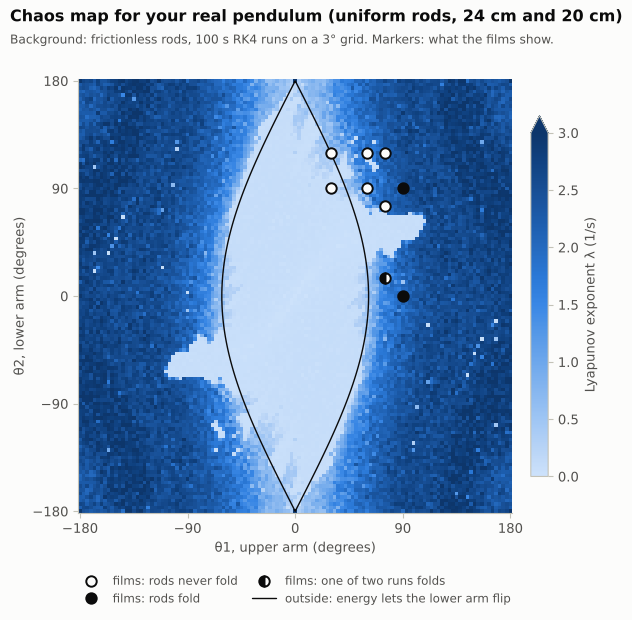

In [18]:
# Figure 6: chaos map for the rod pendulum, with what the films show
FILM_MARK = {"none": dict(marker="o", mfc=SURF, mec=INK, ms=7.5, mew=1.4),
             "fold": dict(marker="o", mfc=INK, mec=INK, ms=7.5, mew=1.4),
             "mixed": dict(marker="o", fillstyle="left", mfc=INK, mfcalt=SURF, mec=INK, ms=7.5, mew=1.4)}
full_r = np.concatenate([lam_rmap[:0:-1, ::-1], lam_rmap], axis=0)
r1_full = np.concatenate([-r1[:0:-1], r1])
fig = plt.figure(figsize=(6.2, 6.1))
side = 0.70
ax = fig.add_axes([0.11, 0.20, side, side * 6.2 / 6.1])
cax = fig.add_axes([0.11 + side + 0.03, 0.26, 0.028, side * 6.2 / 6.1 - 0.12]); cax.grid(False)
hr = grid_r / 2
im = ax.imshow(full_r.T, origin="lower", cmap=LinearSegmentedColormap.from_list("blue_seq", RAMP), vmin=0, vmax=3.0,
               extent=[r1_full[0] - hr, r1_full[-1] + hr, r2[0] - hr, r2[-1] + hr], interpolation="nearest", aspect="equal")
ax.grid(False)
Kr = P_ROD["D"] * np.cos(np.deg2rad(T1)) + P_ROD["F"] * np.cos(np.deg2rad(T2))
ax.contour(T1, T2, Kr, levels=[P_ROD["D"] - P_ROD["F"]], colors=[INK], linewidths=1.0)
for rel, _ in EXP:
    ax.plot([rel[0]], [rel[1]], ls="none", zorder=5, **FILM_MARK[film_kind[rel]])
ax.set_xticks(range(-180, 181, 90)); ax.set_yticks(range(-180, 181, 90))
ax.set_xlabel("θ1, upper arm (degrees)"); ax.set_ylabel("θ2, lower arm (degrees)")
cb = fig.colorbar(im, cax=cax, extend="max")
cb.set_label("Lyapunov exponent λ (1/s)", color=INK2); cb.outline.set_edgecolor(AXIS)
cb.ax.tick_params(color=AXIS, labelcolor=INK2)
handles = [Line2D([], [], ls="none", label="films: " + LABEL[k].replace("one run", "one of two runs"), **FILM_MARK[k])
           for k in ("none", "fold", "mixed")]
handles.append(Line2D([], [], color=INK, lw=1.0, label="outside: energy lets the lower arm flip"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, columnspacing=1.2)
suptitle(fig, "Chaos map for your real pendulum (uniform rods, 24 cm and 20 cm)",
         f"Background: frictionless rods, {T_rmap} s RK4 runs on a {grid_r:g}° grid. Markers: what the films show.")
fig.savefig("fig6_rods_map.png")
plt.show()

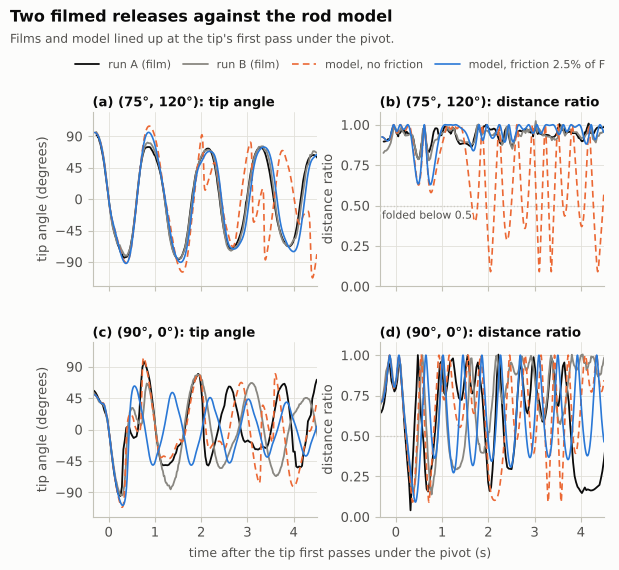

In [19]:
# Figure 7: two filmed releases against the rod model with and without friction
fig, axes = plt.subplots(2, 2, figsize=(6.6, 5.4), sharex=True)
styles = [("run A (film)", dict(color=INK, lw=1.3)), ("run B (film)", dict(color=MUTED, lw=1.3)),
          ("model, no friction", dict(color=ORANGE, lw=1.2, ls=(0, (4, 2.5)))),
          (f"model, friction {FRICTION:.1%} of F", dict(color=BLUE, lw=1.2))]
letters = iter("abcd")
for row, rel in zip(axes, [(75, 120), (90, 0)]):
    curves = [(r["t"] - r["t_cross"], r["phi"], r["rho"]) for r in films[rel]]
    curves += [(m["t"] - m["t_cross"], m["phi"], m["rho"]) for m in (free[rel], fric[rel])]
    for (tt, phi, rho), (label, st) in zip(curves, styles):
        row[0].plot(tt, phi, label=label, **st)
        row[1].plot(tt, rho, **st)
    name = f"({rel[0]}°, {rel[1]}°)"
    row[0].set_title(f"({next(letters)}) {name}: tip angle", fontsize=9.5, pad=4)
    row[1].set_title(f"({next(letters)}) {name}: distance ratio", fontsize=9.5, pad=4)
    row[0].set_ylabel("tip angle (degrees)"); row[0].set_ylim(-125, 125); row[0].set_yticks(range(-90, 91, 45))
    row[1].set_ylabel("distance ratio"); row[1].set_ylim(0, 1.08); row[1].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    row[1].axhline(0.5, color=INK2, lw=0.8, ls=(0, (1, 2)), zorder=0)
axes[0, 1].text(-0.3, 0.47, "folded below 0.5", ha="left", va="top", fontsize=7.8, color=INK2, path_effects=HALO)
fig.supxlabel("time after the tip first passes under the pivot (s)", fontsize=9, color=INK2, y=0.01)
for ax in axes.ravel():
    ax.set_xlim(-0.35, 4.5)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.955), fontsize=8,
           handlelength=2.2, columnspacing=1.1)
suptitle(fig, "Two filmed releases against the rod model", "Films and model lined up at the tip's first pass under the pivot.")
fig.subplots_adjust(top=0.84, bottom=0.09, hspace=0.32, wspace=0.28)
fig.savefig("fig7_films_vs_model.png")
plt.show()

In [20]:
# How much does the friction value matter? The films don't pin it down well.
film_share = {rel: np.mean([r["folds"] > 0 for r in films[rel]]) for rel, _ in EXP}
print("friction (of F) | starts that fold (of 9), releases in the order above | RMS over 4 s | fold mismatch")
for frac in ([0, 0.01, 0.025, 0.05] if FAST else [0, 0.01, 0.015, 0.02, 0.025, 0.03, 0.04, 0.05]):
    m, nf = model_runs(frac * P_ROD["F"]), nearby_folds(frac * P_ROD["F"])
    mismatch = sum(abs(nf[rel] / len(NEAR) - film_share[rel]) for rel, _ in EXP)
    print(f"{frac:14.1%}  | {list(nf.values())} | {rms_no_fold_runs(m):8.1f} deg | {mismatch:.2f}")

friction (of F) | starts that fold (of 9), releases in the order above | RMS over 4 s | fold mismatch


          0.0%  | [0, 0, 0, 0, 1, 4, 9, 9, 8] |     20.5 deg | 1.94


          1.0%  | [0, 0, 0, 0, 0, 1, 3, 9, 6] |     13.5 deg | 1.28


          1.5%  | [0, 0, 0, 0, 0, 0, 6, 9, 5] |     13.9 deg | 1.61


          2.0%  | [0, 0, 0, 0, 0, 1, 5, 9, 4] |     11.6 deg | 1.72


          2.5%  | [0, 0, 0, 0, 0, 0, 1, 9, 3] |      9.8 deg | 1.28


          3.0%  | [0, 0, 0, 0, 0, 0, 2, 9, 3] |      9.0 deg | 1.39


          4.0%  | [0, 0, 0, 0, 0, 0, 0, 9, 2] |      8.2 deg | 1.28


          5.0%  | [0, 0, 0, 0, 0, 0, 0, 9, 1] |      7.8 deg | 1.39


How to read this:

* **What the films show.** In six of the nine releases the two runs stay within 11° to 26° of each other for the whole 4.5 s and the rods never fold. The rods fold only when the upper rod starts horizontal, (90°, 0°) and (90°, 90°), plus one of the two runs of (75°, 15°). That run already bends differently in its first swing, which is too early for chaos, so the two runs were probably not released the same way.
* **Compared with the first analysis.** The films back up "chaotic" for (90°, 0°) and (90°, 90°) and "stable" for (60°, 90°) and (75°, 75°). They don't back up "chaotic" for (30°, 120°) and (60°, 120°): their runs repeat each other just as well as the stable ones. A path can look messy and still repeat; chaos means it doesn't.
* **The frictionless model** is chaotic for 8 of the 9 releases in the long run, but within 4.5 s most of that wouldn't show yet. It clearly disagrees with the films for (75°, 120°), where it folds at all nine starts, and (75°, 75°), four of nine. Neither folds once in four films.
* **With friction** of 2.5% of F in the middle hinge, those folds go away while (90°, 0°) still folds, and the tip-angle error drops by about half. Anything from 1% to 5% beats no friction, so the films can't pin the value down. Measuring it is easy, though: clamp the upper rod and see how much amplitude the lower rod loses per swing (about 6° at 2.5% of F, the same for wide and narrow swings if it really is dry friction).

## 10. Checks worth quoting in the paper

* **Step size:** halving the RK4 step (0.002 s → 0.001 s) should not change which starts count as chaotic.
* **Run length:** for regular starts λ keeps falling as runs get longer; for chaotic starts it settles. The sweep saved λ at 50, 100, 200 and 400 s.
* **A different integrator:** SciPy's adaptive DOP853 solver at very tight tolerances should agree with RK4 until chaos amplifies the last digits.

In [21]:
# Step-size check on a 1 degree grid
ang_c = np.arange(0, 180.0001, 1.0); nc = len(ang_c)
a = lyapunov(two_configs(ang_c), T=200, dt=0.002)["lam"]
b = lyapunov(two_configs(ang_c), T=200, dt=0.001)["lam"]
print(f"step-size check: {np.mean((a > THRESH) == (b > THRESH)):.1%} of 1-degree starts get the same "
      f"chaotic/regular label with dt = 0.002 s and 0.001 s")
for name, sl in (("theta2 = 0", slice(0, nc)), ("theta2 = theta1", slice(nc, 2 * nc))):
    print(f"  {name}: onset with dt=0.002: {onset(ang_c, a[sl], THRESH)[0]:g} deg, with dt=0.001: {onset(ang_c, b[sl], THRESH)[0]:g} deg")

# Run-length check from the sweep's checkpoints
reg = lam_down < THRESH
print("\nrun-length check (theta2 = 0 sweep), median lambda of regular vs chaotic starts:")
for tc in sorted(sw["lam_at"]):
    v = sw["lam_at"][tc][:n]
    print(f"  after {tc:3d} s: regular {np.nanmedian(v[reg]):.3f} /s, chaotic {np.nanmedian(v[~reg]):.3f} /s")

# Independent integrator
from scipy.integrate import solve_ivp
def f_ivp(t, y):
    a1, a2 = accel(y[0], y[1], y[2], y[3], **P)
    return [y[2], y[3], a1, a2]
print("\nRK4 vs DOP853 (rtol = 1e-12), largest angle difference:")
for s1, s2 in ((60, 0), (120, 0)):
    y0c = initial_state(s1, s2)
    ts, ys = integrate(y0c, 20.0, 0.002, every=500)
    ref = solve_ivp(f_ivp, (0, 20), y0c[:, 0], method="DOP853", rtol=1e-12, atol=1e-12, t_eval=ts)
    dev = np.max(np.abs(ys[:, :2, 0] - ref.y[:2].T), axis=1)
    print(f"  start ({s1}, {s2}) deg: after 1 s {dev[1]:.0e} rad, 10 s {dev[10]:.0e} rad, 20 s {dev[20]:.0e} rad")

step-size check: 100.0% of 1-degree starts get the same chaotic/regular label with dt = 0.002 s and 0.001 s
  theta2 = 0: onset with dt=0.002: 67 deg, with dt=0.001: 67 deg
  theta2 = theta1: onset with dt=0.002: 80 deg, with dt=0.001: 80 deg

run-length check (theta2 = 0 sweep), median lambda of regular vs chaotic starts:
  after  50 s: regular 0.080 /s, chaotic 0.985 /s
  after 100 s: regular 0.046 /s, chaotic 0.975 /s
  after 200 s: regular 0.026 /s, chaotic 1.000 /s
  after 400 s: regular 0.015 /s, chaotic 0.999 /s

RK4 vs DOP853 (rtol = 1e-12), largest angle difference:


  start (60, 0) deg: after 1 s 6e-10 rad, 10 s 5e-10 rad, 20 s 4e-09 rad


  start (120, 0) deg: after 1 s 1e-09 rad, 10 s 3e-05 rad, 20 s 1e-01 rad


## 11. Limits of this model (say these in the paper)

* **Point masses vs rods.** Sections 1 to 7 use point masses on massless 1 m rods, like the original code. Sections 8 and 9 model the real rods, assuming uniform rods with mass proportional to length because the masses weren't measured.
* **Friction.** Sections 1 to 8 have no friction at all. Section 9 adds one friction torque in the middle hinge, picked by comparing with the films. Friction at the top pivot and air drag are left out, and the films lose some swing amplitude that this model can't explain.
* **Short films.** Each run was tracked for about 5 s and each release was filmed at most twice. That's not enough to measure λ from the experiment.
* **Finite runs and chosen thresholds.** λ is measured over a finite time, and the 0.03 /s and 0.1 /s boundaries are judgment calls. The run-length check shows the split between regular and chaotic is clear for most angles, but thin weakly chaotic layers exist near the main onset. The fold criterion (distance ratio below 0.5) and the 45° limit for the films are choices too.
* **Starting from rest.** Every result here is for releases with zero initial speed.